<img src = "https://drive.google.com/uc?export=view&id=1kdkuhRlu2yXQr6DEZKOu4esM987WDSsw" alt = "Encabezado NS4DA" width = "100%">  </img>

**Proyecto · Informe escrito final**
---
**Vulnerabilidad de la red doméstica de carga aérea de Estados Unidos ante fallos simultáneos de aeropuertos · 2025**

Este notebook es el informe resumen del proyecto, organizado según la plantilla del curso. El análisis completo, reproducible y con todo el código está en el notebook
[`NS4DA_Desarrollo_carga_aerea_2025.ipynb`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/blob/main/NS4DA_Desarrollo_carga_aerea_2025.ipynb) ([versión para lectura en nbviewer](https://nbviewer.org/github/dnunezq/Network_Science_air-cargo-network-robustness/blob/main/NS4DA_Desarrollo_carga_aerea_2025.ipynb)), en la raíz de este repositorio. Las secciones del notebook completo se citan entre paréntesis, por ejemplo (§4.2).

## **0. Integrantes del equipo de trabajo**
---

1. \*\*\*\*\*\*\*\* · \*\*\*\*\*\*\*\*\*\*
2. \*\*\*\*\*\*\*\* · \*\*\*\*\*\*\*\*\*\*

## **1. Informe escrito**
---

### **1.1. Cita del artículo de referencia**
---

Zhou, H., & Razavi, S. (2026). An explanatory composite metric for air cargo network robustness: incorporating pairwise synergistic effects. *Scientific Reports, 16*, 7071. https://doi.org/10.1038/s41598-026-38153-y

### **1.2. Descripción del problema**
---

La carga aérea doméstica de Estados Unidos está muy concentrada: unas pocas compañías integradoras (FedEx, UPS, Amazon Air) operan redes *hub-and-spoke* en las que casi toda la mercancía pasa por uno o dos centros de clasificación. Esa concentración es eficiente, pero frágil: una tormenta, un cierre de pista o una caída de sistemas puede sacar un aeropuerto de la red durante horas o días.

La pregunta no es solo qué aeropuerto es más importante, sino **qué parejas de aeropuertos no deberían fallar al mismo tiempo**. Al fallar juntas, esas parejas causan un daño adicional a la estructura de la red, por encima de la suma de sus fallos individuales: la **sinergia**. El proyecto calcula esa sinergia para las 4.950 parejas de los 100 aeropuertos con más carga en 2025, explica qué la determina y evalúa qué tan estable es la priorización resultante.

### **1.3. Objetivo y alcance del proyecto**
---

**Objetivo general.** Adaptar la metodología de Zhou y Razavi (2026) a los datos de 2025 y aportar un análisis de la firmeza de sus resultados.

**Objetivos específicos.**

1. Construir, con trazabilidad completa, la red de carga aérea doméstica de 2025, anual y por trimestres, sobre los 100 aeropuertos de mayor carga.
2. Caracterizar la red antes de perturbarla: medidas globales y locales, centralidades, tipo de red, comunidades y asortatividad.
3. Calcular tres medidas de robustez, simular todos los fallos individuales y dobles, y construir el índice compuesto de sinergia.
4. Explicar el índice con una regresión para datos de red (MRQAP) y evaluar su firmeza frente a trimestres, definiciones de enlace, caminos entre aeropuertos supervivientes y operadores.
5. Entregar un explorador interactivo (Atlas Cargo) que use exactamente estos resultados.

**Alcance.** El índice describe **vulnerabilidad estructural** de una red binaria: la existencia de conexiones y caminos. No estima toneladas perdidas, costes, probabilidades de fallo ni capacidad de desvío, y no se presenta como réplica numérica del estudio de 2022. Los resultados son descriptivos y exploratorios, no causales.

### **1.4. Caso de estudio**
---

El artículo estudia la red doméstica de carga aérea de Estados Unidos de 2022 con los 100 aeropuertos de mayor carga, que concentran más del 92 % del volumen. Para cada pareja de aeropuertos simula su retiro conjunto y mide el efecto sobre tres medidas de robustez: **eficiencia global**, **eficiencia local** y **conectividad natural**. La sinergia de una pareja es el daño conjunto menos la suma de los daños individuales. Las tres sinergias se combinan en un índice compuesto con pesos por entropía, y el índice se explica con MRQAP en cinco modelos (M1–M5), más un sexto modelo (M6) como sensibilidad.

El proyecto reproduce ese procedimiento con los datos de **2025** (§5–§8). Además añade, como aporte propio:

- **Caracterización estructural de la red** (§4.2): centralidades, comunidades y comparación con los modelos aleatorio, de mundo pequeño y preferencial.
- **Comparación trimestral** (§9.1) con los mismos 100 aeropuertos.
- **Sensibilidad a la definición de enlace** (§9.2–§9.3) con cuatro reglas.
- **Descomposición del daño** entre efecto de composición y alargamiento real de caminos (§9.4).
- **Retiro de operadores completos** (§9.5) y una segunda forma de calcular los valores p de la regresión (§9.6).
- **Explorador interactivo** con un laboratorio didáctico.

### **1.5. Conjunto de datos de la red**
---

**Fuente.** Bureau of Transportation Statistics (BTS), tabla **T-100 Domestic Segment (All Carriers)**, año 2025, doce meses, descargada el 4 de octubre de 2026 desde el [formulario de TranStats](https://transtats.bts.gov/DL_SelectFields.aspx?gnoyr_VQ=GEE&QO_fu146_anzr=Nv4+Pn44vr45) ([diccionario de variables](https://transtats.bts.gov/Fields.asp?gnoyr_VQ=GEE)). Cada fila es el agregado mensual de un segmento origen → destino operado por un transportista con un tipo de aeronave y una clase de servicio. Las variables usadas son la carga (`FREIGHT`, en libras), los identificadores de aeropuerto, el mes, el transportista y la clase de servicio.

**Dónde están los datos.** Todos los datos de entrada están incluidos en este repositorio, en [`data/raw/`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/tree/main/data/raw), y el notebook comprueba su huella SHA-256 antes de usarlos. [`data/LEEME_datos_BTS_T100_2025.txt`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/blob/main/data/LEEME_datos_BTS_T100_2025.txt) describe la descarga y las 45 columnas.

| Archivo | Contenido | Uso |
|---|---|---|
| `BTS_T100_Domestic_Segment_All_Carriers_2025.zip` (14,5 MB) | 458.793 filas, 45 columnas | Red y análisis |
| `coordenadas_bts.csv` (BTS *Master Coordinate*) | Latitud y longitud de cada versión de aeropuerto | Mapas y distancia geográfica de la regresión |
| `ne_110m_admin_0_countries.geojson` (Natural Earth) | Contorno de los países | Fondo de los mapas |

**De los datos a la red** (§2–§4):

- **Limpieza.** Se conservan las filas con carga positiva entre aeropuertos distintos: de 458.793 quedan 191.845.
- **Selección.** Se toman los 100 aeropuertos con mayor carga anual; los segmentos entre ellos reúnen el 94,5 % de la carga.
- **Agregación.** Las filas se suman por ruta y mes.
- **Construcción.** Para cada período se forma una red **no dirigida y binaria**: hay enlace si hubo carga en cualquier sentido.

| Red | Nodos | Enlaces | Densidad |
|---|---|---|---|
| Año 2025 | 100 | 2.441 | 0,493 |
| Trimestres T1–T4 | 100 | 1.818 a 1.994 | 0,37 a 0,40 |

Las tablas resultantes (rutas mensuales, enlaces, pares con su sinergia, centralidades, sensibilidades) están en [`resultados/`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/tree/main/resultados).

### **1.6. Enfoque de Ciencia de Redes implementado**
---

| Etapa | Modelos y métodos de ciencia de redes | Sección |
|---|---|---|
| Modelamiento | Grafo no dirigido y binario de 100 aeropuertos; cinco redes (año y trimestres) | §4.1 |
| Exploración | Densidad, distancia media, diámetro, agrupamiento, transitividad, asortatividad, núcleo k-core; centralidades de grado, intermediación, cercanía y autovector | §4.2 |
| Tipo de red | Comparación con los modelos de **Erdős–Rényi** (aleatoria), **Watts–Strogatz** (mundo pequeño) y **Barabási–Albert** (preferencial) por agrupamiento, longitud de caminos y hubs | §4.2 |
| Comunidades | Método de **Louvain** (modularidad Q), estabilidad entre 20 ejecuciones con información mutua normalizada | §4.2 |
| Robustez | **Eficiencia global** (Latora y Marchiori), **eficiencia local** y **conectividad natural** (espectral) | §5 |
| Ataques | Retiro de nodos: 100 fallos individuales y 4.950 dobles en cada una de las cinco redes; impacto y **sinergia** | §6 |
| Índice | Normalización por máximo absoluto y pesos por **entropía** | §7 |
| Explicación | Regresión para datos de red **MRQAP** (permutación de nodos), modelos M1–M6 | §8 |
| Firmeza | Correlación de rangos de **Spearman**, coincidencia del top 20, reglas de enlace, descomposición de caminos, capas por operador | §9 |

Las medidas de robustez se calculan con una implementación propia y exacta, acelerada con numba y validada contra NetworkX en 19 grafos de prueba. Todo lo demás usa NetworkX, NumPy, SciPy y pandas.

### **1.7. Enlace al código fuente**
---

**Repositorio:** https://github.com/dnunezq/Network_Science_air-cargo-network-robustness

- **Notebook completo, ejecutado y reproducible:** [`NS4DA_Desarrollo_carga_aerea_2025.ipynb`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/blob/main/NS4DA_Desarrollo_carga_aerea_2025.ipynb) · [lectura en nbviewer](https://nbviewer.org/github/dnunezq/Network_Science_air-cargo-network-robustness/blob/main/NS4DA_Desarrollo_carga_aerea_2025.ipynb).
- **Código del análisis:** [`src/`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/tree/main/src). Son módulos de Python que el notebook importa, con sus pruebas.
- **Código de la app Atlas Cargo:** [`app/`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/tree/main/app). Es una app estática en HTML, CSS y JavaScript con Leaflet.
- **App en un solo archivo:** [`Atlas_Carga_Aerea_2025.html`](https://github.com/dnunezq/Network_Science_air-cargo-network-robustness/blob/main/Atlas_Carga_Aerea_2025.html). Se descarga y se abre con doble clic, sin servidor ni internet.

| Carpeta o archivo | Contenido |
|---|---|
| `PIF-NS4DA-4.ipynb` | Este informe resumen |
| `NS4DA_Desarrollo_carga_aerea_2025.ipynb` | Análisis completo: datos, red, medidas, simulación, índice, regresión, firmeza y conclusiones |
| `src/` | Módulos del análisis y pruebas |
| `data/raw/` | Datos de entrada |
| `cache/` | Cachés de la simulación de fallos, verificadas por huella |
| `resultados/`, `figuras/` | Tablas y figuras exportadas por el notebook |
| `app/` | Código de la app; `app/dist/data/` contiene los JSON que exporta el notebook |

**Cómo ejecutarlo.** El notebook completo corre desde la raíz del repositorio en unos 60 a 70 segundos, gracias a las cachés:

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
python src/ejecutar_notebook.py NS4DA_Desarrollo_carga_aerea_2025.ipynb
python -m unittest discover -s src -p "test*.py"
```

También puede abrirse con Jupyter y ejecutarse celda por celda.

### **1.8. Enlace al video explicativo**
---

*Pendiente.* El video explicativo está en preparación; el enlace se agregará aquí cuando esté disponible.

### **1.9. Contribuciones de los miembros del equipo**
---

| Miembro del equipo | Rol | Actividades/contribuciones |
|---|---|---|
| \*\*\*\*\*\*\*\* | Coordinador y responsable de diapositivas | Revisión del artículo y los datos; planeación de la estrategia; coordinación del equipo y presentación. |
| \*\*\*\*\*\*\*\* | Responsable del notebook | Revisión del artículo y los datos; planeación de la estrategia; preparación del notebook. |

### **1.10. Uso de herramientas de inteligencia artificial para la preparación de este entregable**
---

Se utilizaron asistentes de inteligencia artificial (Codex de OpenAI y Claude de Anthropic) para localizar fuentes, explicar el artículo, programar, documentar, probar y visualizar, incluida la app Atlas Cargo. Las cifras del informe se obtuvieron ejecutando el código sobre los datos con trazabilidad; ninguna se tomó directamente de una respuesta de la herramienta. El equipo revisó las fuentes, los supuestos, los métodos y los textos, y asume la responsabilidad por el contenido. La asistencia no reemplaza la validación académica.

### **1.11. Resultados**
---

**La red.** La red anual es densa: cada aeropuerto conecta directamente con la mitad de los demás, la distancia media es de 1,51 escalas y el diámetro es 3 (§4.2). Tiene un patrón *hub-and-spoke*, con asortatividad negativa (−0,16) y un núcleo k-core de 53 aeropuertos.

En las tres propiedades del curso, la red tiene agrupamiento alto (0,75 frente a 0,49 de una red aleatoria), caminos cortos y hubs (desviación del grado 21,4 frente a 4,8 aleatoria). Es el **perfil preferencial (Barabási–Albert)**, y también el modelo simulado más cercano. No se describe como libre de escala: el grado solo va de 6 a 89. Las comunidades son débiles: modularidad 0,12 y particiones poco estables.

**Red anual de carga entre los 100 aeropuertos (200 enlaces con mayor carga)**

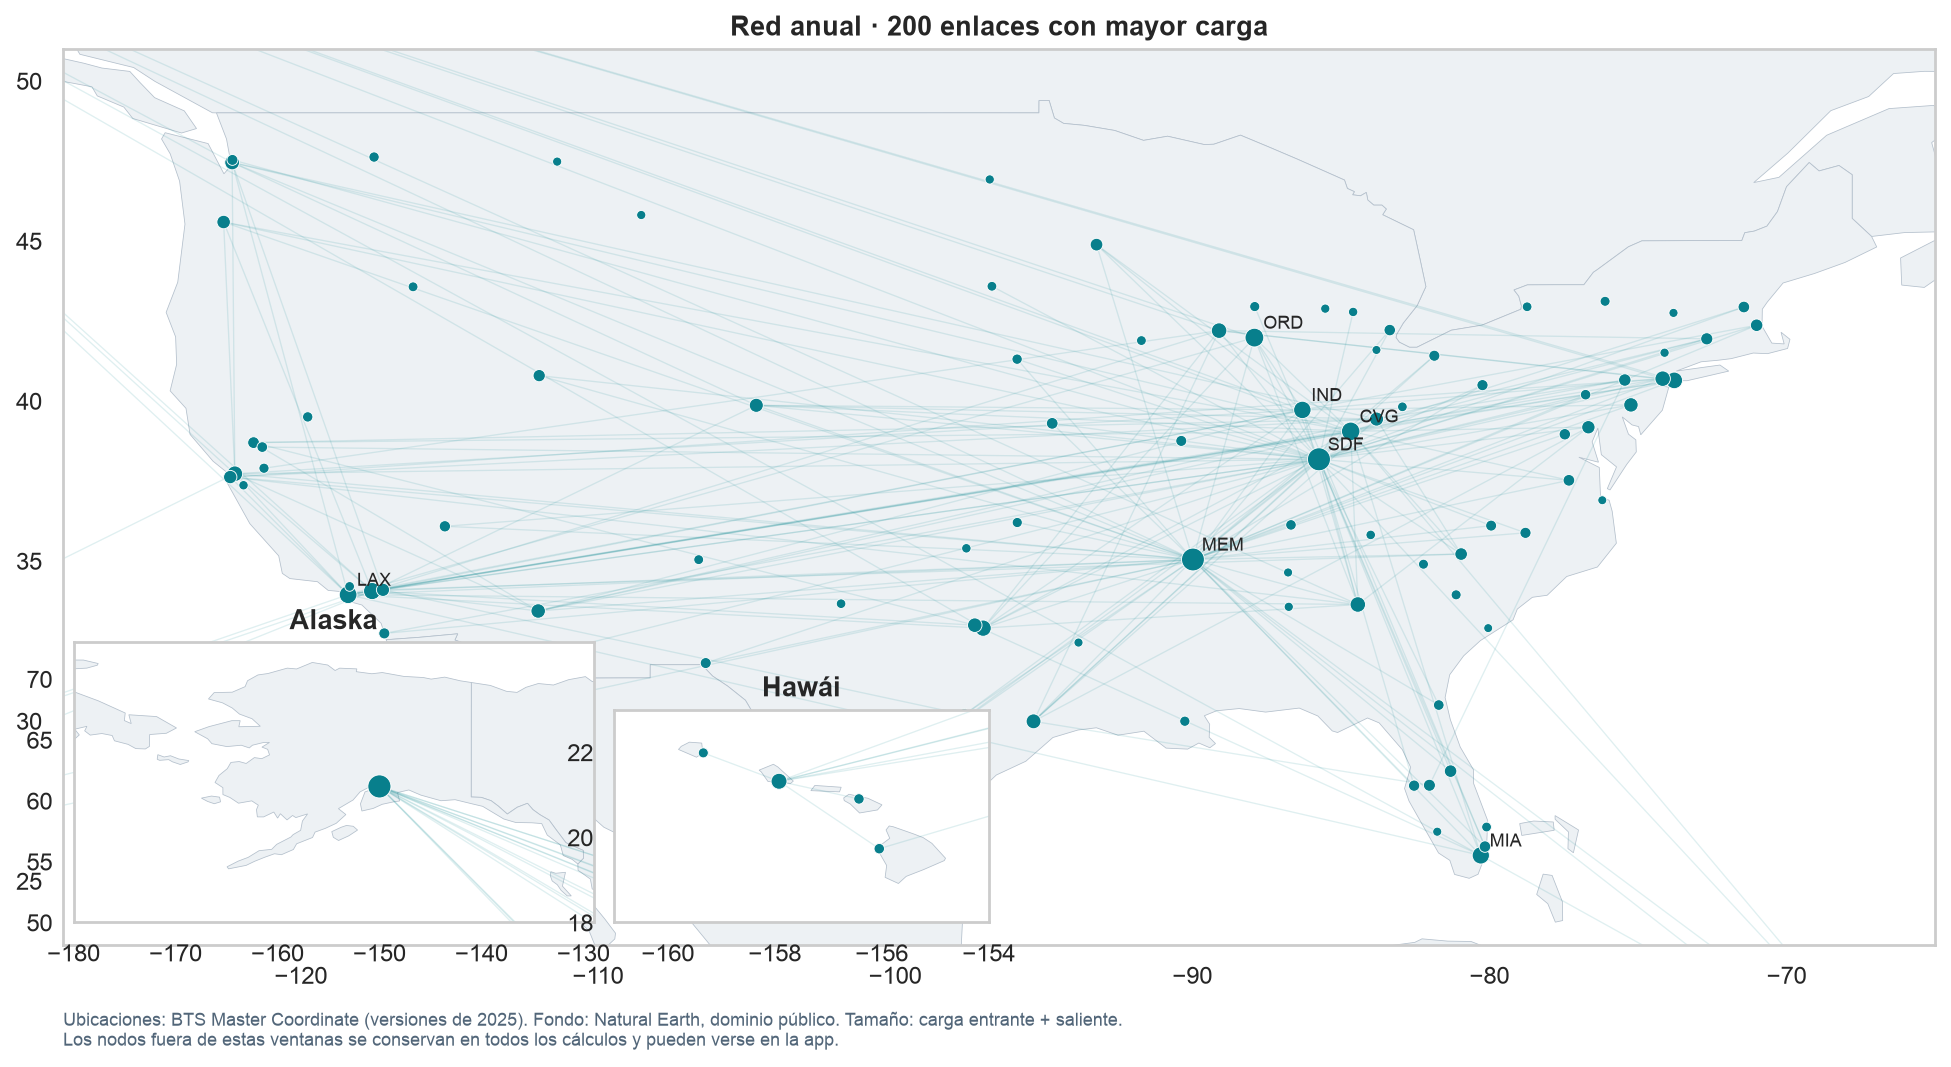

**La red frente a los tres modelos del curso**

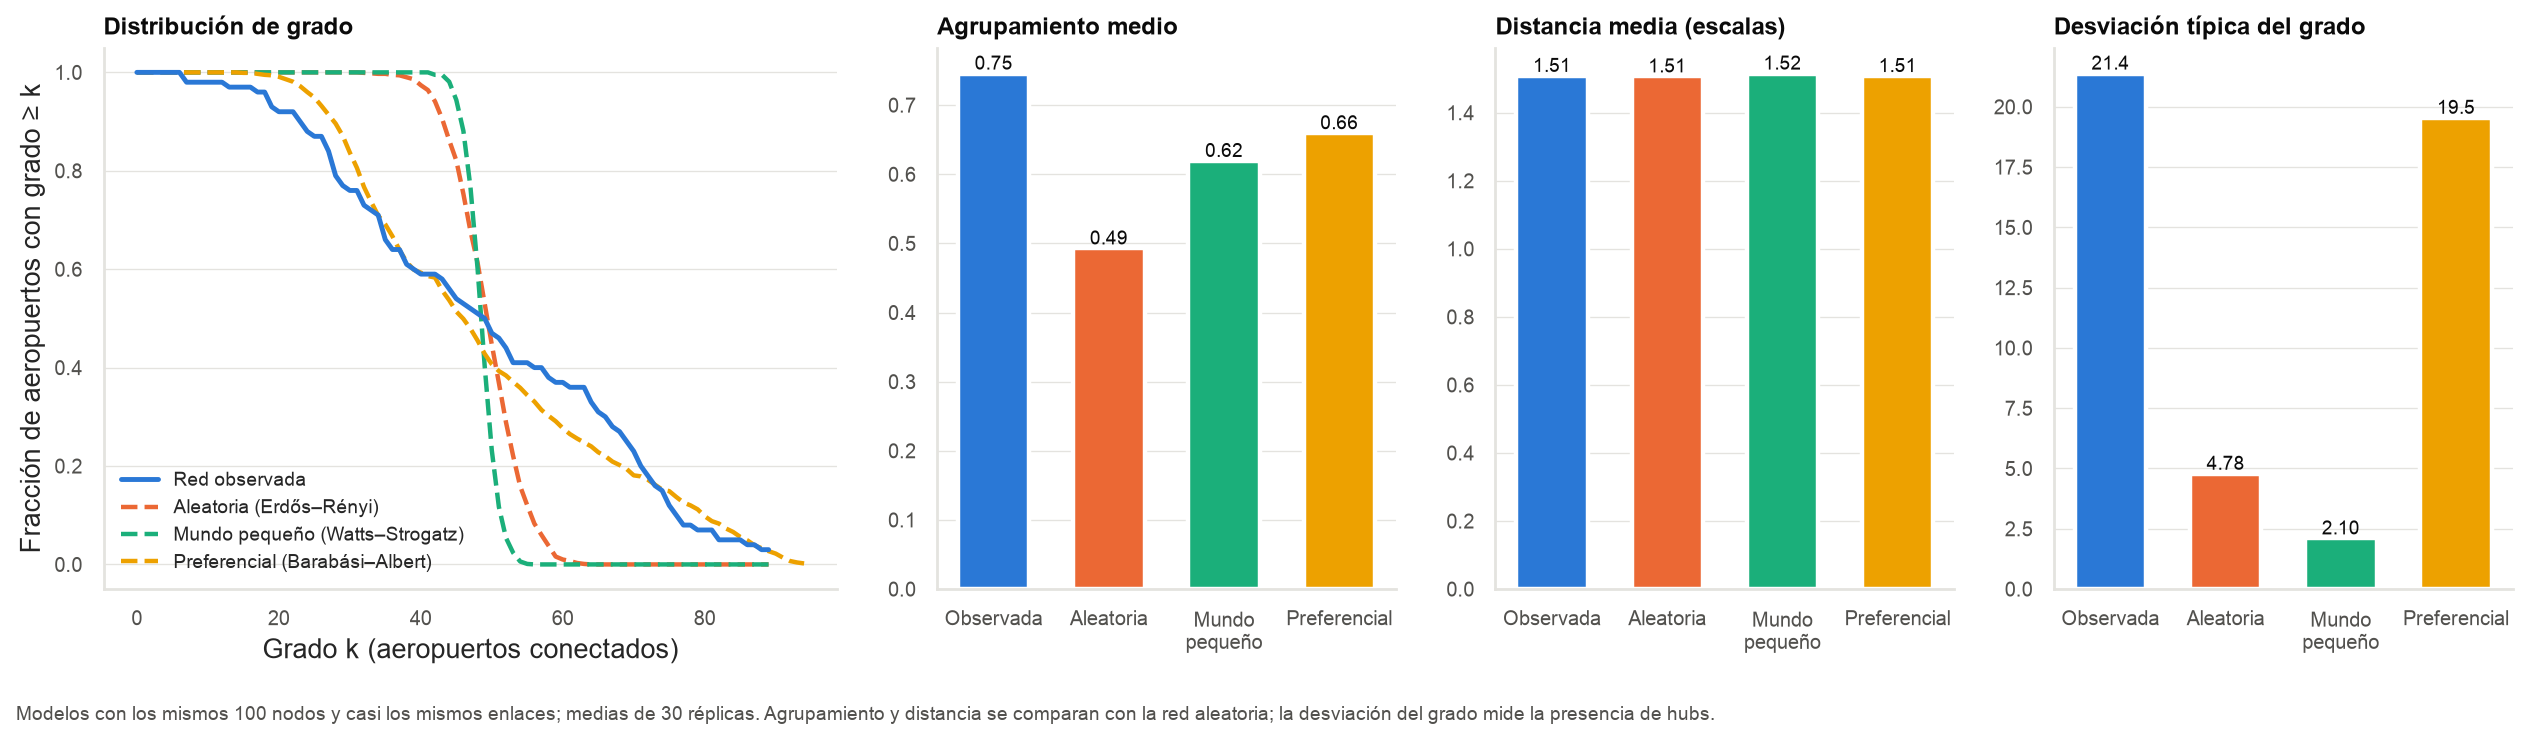

In [1]:
from pathlib import Path
from IPython.display import Image, Markdown, display

def figura(archivo, titulo):
    display(Markdown(f'**{titulo}**'))
    display(Image(filename=str(Path('figuras')/archivo), width=950))

figura('02_mapa_red.png', 'Red anual de carga entre los 100 aeropuertos (200 enlaces con mayor carga)')
figura('16_distribucion_grado_modelos.png', 'La red frente a los tres modelos del curso')

**Medidas de robustez y sinergia** (§5–§7). Antes de cualquier fallo, la red anual tiene eficiencia global 0,746, eficiencia local 0,873 y conectividad natural 52,7. Los pesos por entropía de las tres sinergias son 0,271, 0,428 y 0,301, casi idénticos a los del artículo (0,279, 0,421 y 0,299). El índice compuesto va de −1 a 1.

| Puesto | Pareja | Índice de sinergia | Enlace directo |
|---|---|---|---|
| 1 | SDF–SEA (Louisville–Seattle) | 0,684 | No |
| 2 | SDF–SFO (Louisville–San Francisco) | 0,591 | No |
| 3 | MEM–ORD (Memphis–Chicago O'Hare) | 0,472 | Sí |
| 4 | ONT–IAD (Ontario–Washington Dulles) | 0,417 | No |
| 5 | IND–RFD (Indianápolis–Rockford) | 0,413 | No |
| 6 | RFD–BNA (Rockford–Nashville) | 0,405 | No |
| 7 | ONT–FLL (Ontario–Fort Lauderdale) | 0,393 | No |
| 8 | RFD–AUS (Rockford–Austin) | 0,371 | No |
| 9 | SDF–SMF (Louisville–Sacramento) | 0,363 | No |
| 10 | RFD–TPA (Rockford–Tampa) | 0,347 | No |

Nueve de las diez parejas con mayor sinergia **no tienen enlace directo**, el mismo patrón del artículo: dos aeropuertos que se respaldan a distancia pierden a la vez las alternativas que cada uno cubría del otro. **Sinergia no es daño total.** MEM–ORD es la pareja que más daña la eficiencia global, pero es la tercera en sinergia, y SDF–SEA es la 56.ª en daño.

**Parejas con mayor sinergia y relación entre sinergia y daño conjunto**

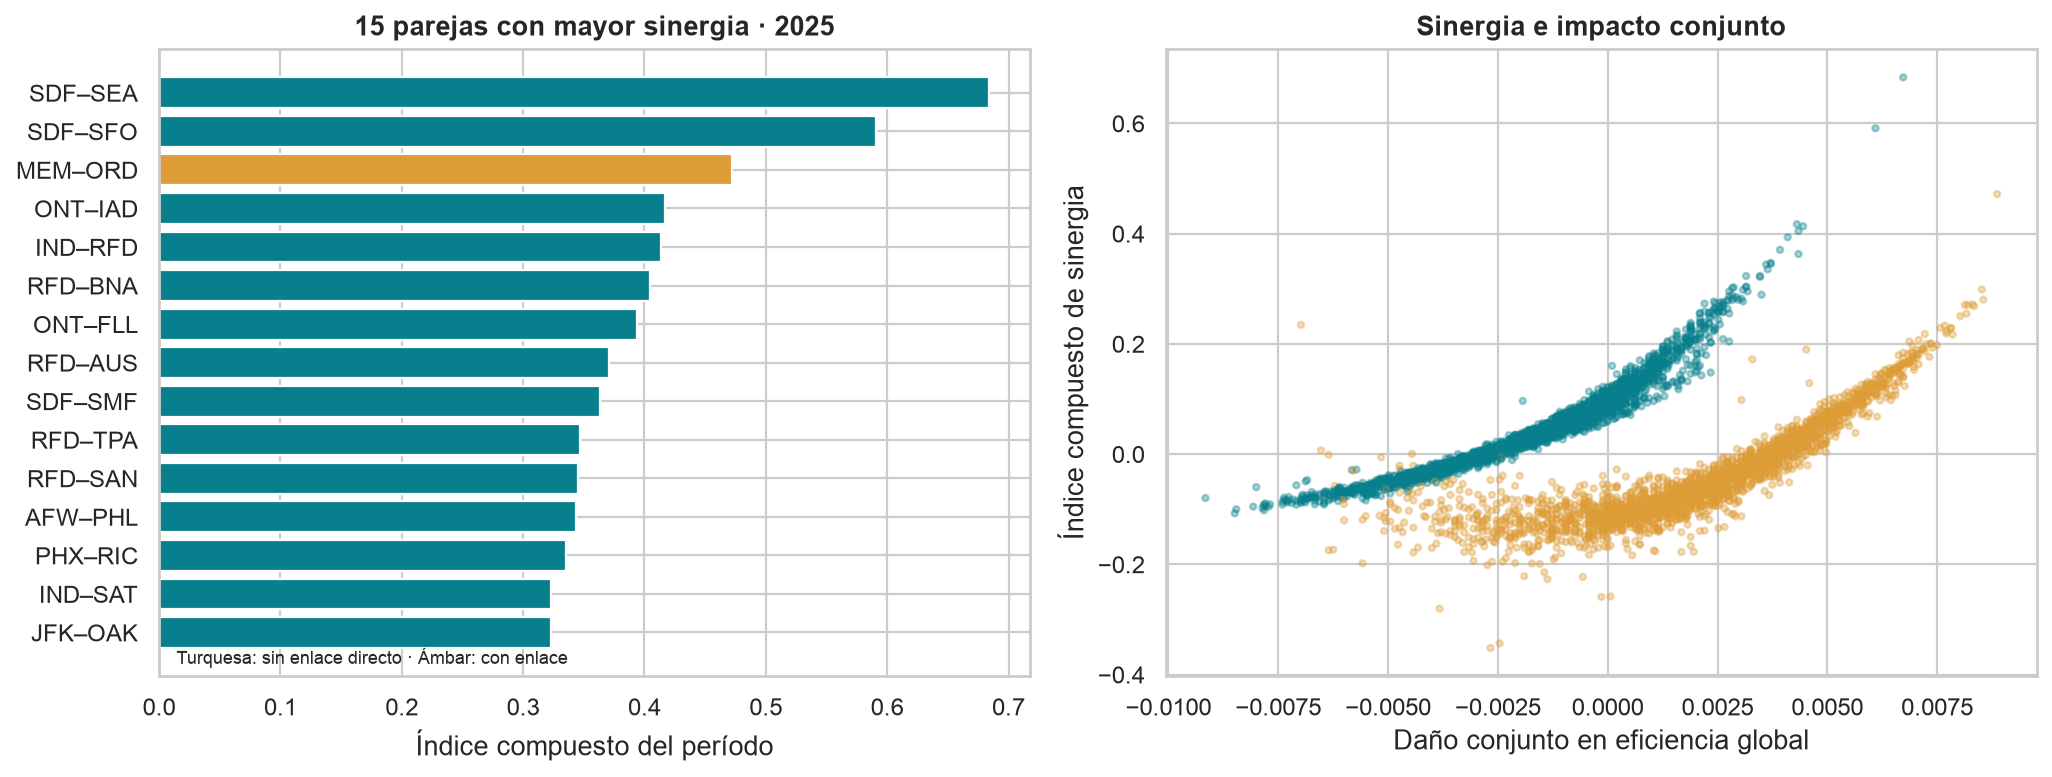

In [2]:
figura('03_ranking_y_impacto.png', 'Parejas con mayor sinergia y relación entre sinergia y daño conjunto')

**Qué explica la sinergia** (§8). La conexión directa y la suma de grados explican casi toda la variación del índice. Por separado, la centralidad (M1) y la conexión directa (M2) explican un 20 % cada una; juntas (M3), el 85 %.

| Modelo | M1 | M2 | M3 | M4 | M5 | M6 |
|---|---|---|---|---|---|---|
| R² 2025 | 0,192 | 0,202 | 0,846 | 0,873 | 0,872 | 0,958 |
| R² artículo, 2022 | 0,153 | 0,139 | 0,691 | 0,739 | 0,739 | — |

- **Conexión directa:** una pareja conectada tiene un índice 0,20 menor. El enlace común se pierde con cualquiera de los dos fallos y cuenta dos veces en la suma de daños individuales.
- **Suma de grados:** sube el índice 0,115 por desviación típica si la pareja no está conectada, y 0,072 si lo está; el artículo encuentra el mismo patrón.

Es un ajuste dentro de la red, no una predicción ni una relación causal.

**Firmeza de los resultados** (§9):

- **Trimestres.** El orden global entre trimestres es parecido (Spearman de 0,70 a 0,75), pero el top 20 coincide solo entre 25 % y 55 %. Las caídas abruptas de una pareja coinciden siempre con un enlace directo nuevo en ese trimestre, a menudo de un solo vuelo.
- **Regla de enlace.** Exigir presencia en todos los meses conserva el 97 % de la carga, pero solo dos de las veinte prioridades (Spearman 0,38). El volumen retenido no garantiza estabilidad del ranking.
- **Núcleo persistente.** Solo **SDF–SEA y SDF–SFO** están en el top 20 de los cuatro trimestres y de las cuatro reglas de enlace.
- **Caminos.** El fallo de SDF–SEA no alarga ningún camino mínimo entre los 98 aeropuertos que quedan: lo que se pierde es redundancia.
- **Operadores.** Sin UPS la red pierde 261 conexiones que ningún otro operador cubre; sin FedEx, 125. En ambos casos sigue conexa.

**Puestos de las parejas prioritarias bajo las cuatro reglas de enlace**

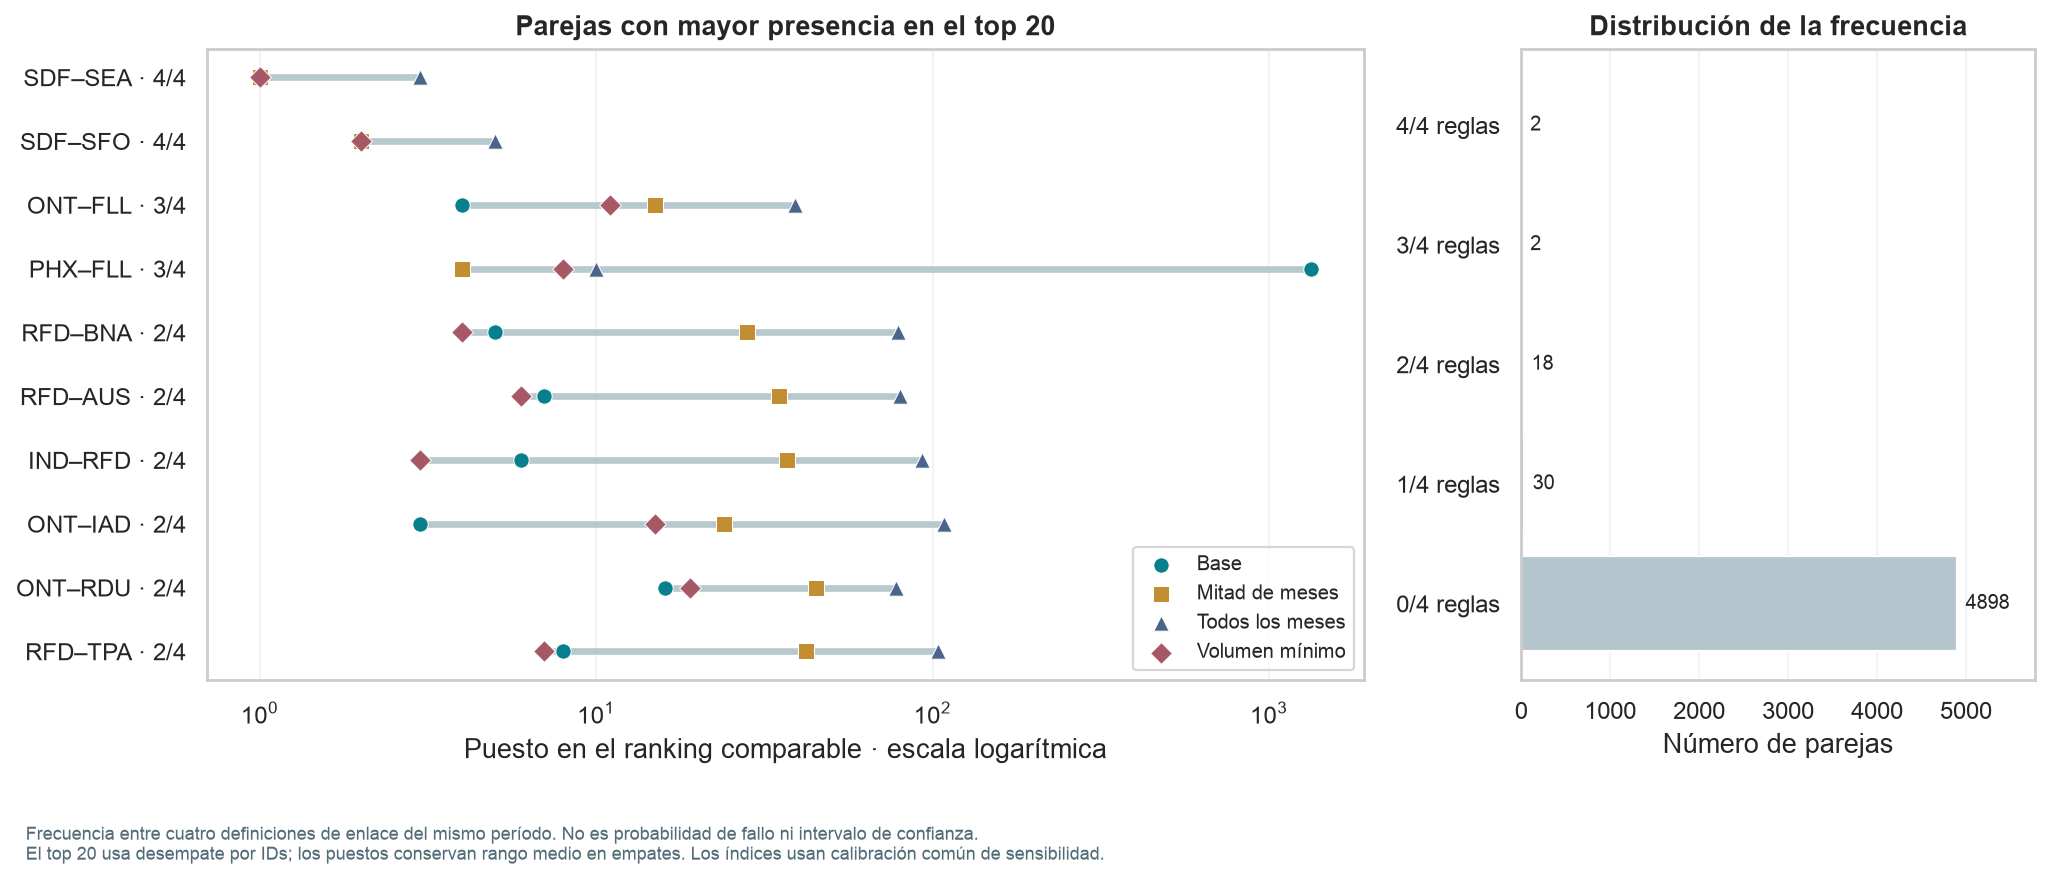

In [3]:
figura('15_estabilidad_parejas.png', 'Puestos de las parejas prioritarias bajo las cuatro reglas de enlace')

**Explorador interactivo Atlas Cargo.** La app muestra los resultados sobre un mapa:

- Permite elegir período, regla de enlace y uno o dos aeropuertos, y simular su retiro.
- Ordena las parejas por sinergia o por daño y muestra la ficha con el cálculo paso a paso.
- Incluye las pestañas de estructura, trimestres, sensibilidad, estabilidad, operadores y modelos.
- Tiene un **Laboratorio** con redes de juguete para ver qué miden las tres medidas y la sinergia.

Todas sus cifras provienen de los JSON que exporta el notebook.

### **1.12. Conclusiones**
---

**Conclusiones.**

1. El patrón del artículo se mantiene en 2025. Los pesos de las tres medidas son casi iguales, las parejas de mayor sinergia son sobre todo parejas sin enlace directo y la conexión directa domina la explicación de la sinergia.
2. La red que se perturba es densa, con hubs y del tipo preferencial, sin comunidades marcadas. En una red así casi todo tiene alternativas, y la sinergia identifica las parejas que eliminan esas alternativas a la vez.
3. Sinergia y daño total responden preguntas distintas y deben presentarse por separado.
4. El ranking completo es frágil ante la definición de enlace y el trimestre: un solo vuelo esporádico puede convertir una pareja en conectada y hundir su sinergia. Aun así existe un núcleo persistente, SDF–SEA y SDF–SFO, que encabeza bajo todas las variantes.
5. La dependencia de un operador es otra dimensión de vulnerabilidad que el índice de aeropuertos no captura.

**Limitaciones.**

- La red binaria ignora frecuencias, capacidades, horarios, direcciones y acuerdos entre operadores: una ruta esporádica pesa igual que una diaria.
- La subred deja fuera aeropuertos pequeños que podrían ofrecer desvíos.
- Al retirar nodos cambia el denominador de las eficiencias, y por eso hay impactos negativos.
- La escala por máximo absoluto es sensible a parejas extremas.
- Las medidas no estiman pérdidas de carga.
- La regresión no tiene validación fuera de muestra y sus contrastes son exploratorios.

**Cómo podría mejorarse.**

- Usar redes ponderadas por frecuencia o carga, y redes dirigidas o multicapa por operador.
- Definir los nodos como mercados urbanos, uniendo aeropuertos de la misma ciudad como SEA y BFI.
- Usar escalas robustas, por ejemplo percentiles, en lugar del máximo absoluto.
- Reconstruir 2022 con el mismo protocolo para comparar cifras y no solo patrones.
- Evaluar la priorización con datos de períodos posteriores.

### **1.13. Referencias**
---

1. Zhou, H., & Razavi, S. (2026). An explanatory composite metric for air cargo network robustness: incorporating pairwise synergistic effects. *Scientific Reports, 16*, 7071. https://doi.org/10.1038/s41598-026-38153-y
2. Latora, V., & Marchiori, M. (2001). Efficient behavior of small-world networks. *Physical Review Letters, 87*, 198701.
3. Wu, J., Barahona, M., Tan, Y.-J., & Deng, H.-Z. (2010). Natural connectivity of complex networks. *Chinese Physics Letters, 27*, 078902.
4. Dekker, D., Krackhardt, D., & Snijders, T. A. B. (2007). Sensitivity of MRQAP tests to collinearity and autocorrelation conditions. *Psychometrika, 72*, 563–581.
5. Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae, 6*, 290–297.
6. Watts, D. J., & Strogatz, S. H. (1998). Collective dynamics of 'small-world' networks. *Nature, 393*, 440–442.
7. Barabási, A.-L., & Albert, R. (1999). Emergence of scaling in random networks. *Science, 286*, 509–512.
8. Clauset, A., Shalizi, C. R., & Newman, M. E. J. (2009). Power-law distributions in empirical data. *SIAM Review, 51*, 661–703.
9. Meléndez Acuña, J. A. (2025). *Network Models*. Material del curso Network Science for Data Analytics, unidad 3.
10. Bureau of Transportation Statistics. *T-100 Domestic Segment (All Carriers)*, 2025. https://transtats.bts.gov/Fields.asp?gnoyr_VQ=GEE
11. Bureau of Transportation Statistics. *Master Coordinate*. https://transtats.bts.gov/Fields.asp?gnoyr_VQ=FLL
12. Hagberg, A., Schult, D., & Swart, P. (2008). Exploring network structure, dynamics, and function using NetworkX. *Proceedings of the 7th Python in Science Conference*, 11–15.
13. Natural Earth. *Admin 0 – Countries, 1:110m*. Dominio público. https://www.naturalearthdata.com/

## **Créditos**
* **Profesores:**
    - Jorge Alfonso Meléndez Acuña
    - Luis Fernando Niño Vásquez
* **Asistente docente y Coordinadora de virtualización:**
    - Angela Maria Arboleda Restrepo
* **Diseño de imágenes:**
    - Tania Valentina Flórez Rincón
    
**Universidad Nacional de Colombia** - *Facultad de Ingeniería*